# Plot results from gamma sweep

## Imports

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [2]:
# --- Load results ---
path = "../data/block_comparison_gamma_sweep.json"
with open(path, "r") as f:
    results_strkeys = json.load(f)

# Convert keys "0.25" -> 0.25 so you can index like results[0.25]
results = {float(k): v for k, v in results_strkeys.items()}

# --- Plot like before ---
gammas = np.array(sorted(results.keys()), dtype=float)
epochs = np.arange(len(results[gammas[0]]["train_loss"]))


## Plot

In [3]:
# Colormap setup
cmap = cm.plasma
norm = Normalize(vmin=gammas.min(), vmax=gammas.max())

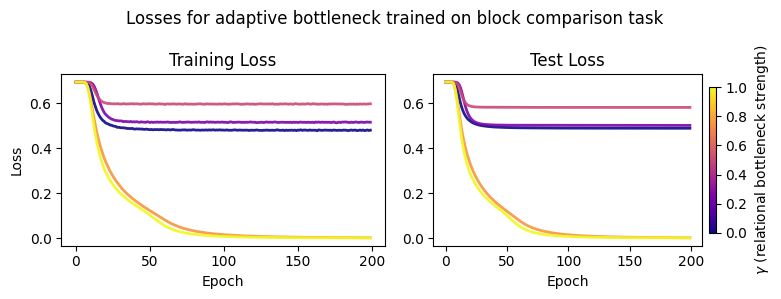

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)

# -------------------------
# Training loss panel
# -------------------------
for g in gammas:
    color = cmap(norm(g))
    axes[0].plot(
        epochs,
        results[g]["train_loss"],
        color=color,
        linewidth=2,
        alpha=0.9
    )

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

# -------------------------
# Testing loss panel
# -------------------------
for g in gammas:
    color = cmap(norm(g))
    axes[1].plot(
        epochs,
        results[g]["test_loss"],
        color=color,
        linewidth=2,
        alpha=0.9
    )

axes[1].set_title("Test Loss")
axes[1].set_xlabel("Epoch")

# -------------------------
# Colorbar (shared)
# -------------------------
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1],
    location="right",
    pad=0.02,
    shrink=0.85
)
cbar.set_label(r"$\gamma$ (relational bottleneck strength)")
plt.suptitle("Losses for adaptive bottleneck trained on block comparison task", fontsize=12)

plt.tight_layout()
plt.show()